# Xem kết quả train – LANL (xác thực Windows/AD)
Chọn kernel **Python (soc-ueba)** ở góc trên bên phải, rồi `Run All`.

In [1]:
import sys, json, pandas as pd, joblib
sys.path.insert(0, '../src')
from IPython.display import Image, display
from config import PROCESSED_DIR, REPORTS_DIR, MODELS_DIR
pd.set_option('display.max_columns', 40)

## 1. So sánh phương án (train ngày 1–7, chọn trên val 8–19, test 20–29)
Ngày 20–29 chưa từng dùng khi thiết kế feature/mô hình. `lanl_online` = mô phỏng triển khai thật từng ngày: cách ly baseline, fan-in, phản hồi IOC (thiết kế SAU khi chẩn đoán test → báo cáo tách riêng).

In [2]:
exp = pd.read_csv(REPORTS_DIR / 'lanl_experiments.csv')
display(exp.round(3))
pd.read_csv(REPORTS_DIR / 'lanl_online.csv').round(3)

,split,method,roc_auc,pr_auc,precision@100,recall@1000,recall@thr,fpr@thr,accounts_caught,alerts_per_day,acc@10/d,acc@25/d,acc@50/d
0,val,stat,0.935,0.042,0.08,0.351,0.231,0.003,26.0,34.2,5.0,13.0,18.0
1,val,ecod,0.944,0.148,0.24,0.537,0.358,0.002,37.0,19.6,13.0,28.0,39.0
2,val,iforest,0.900,0.027,0.06,0.216,0.246,0.011,29.0,99.8,2.0,8.0,15.0
3,val,ae,0.857,0.027,0.03,0.239,0.224,0.009,28.0,81.2,2.0,3.0,7.0
4,val,iforest_lateral,0.965,0.117,0.22,0.582,0.396,0.004,43.0,43.6,13.0,20.0,29.0
5,val,ens_mean,0.924,0.082,0.16,0.567,0.567,0.009,70.0,86.6,8.0,21.0,29.0
6,val,ens_max,0.923,0.030,0.06,0.246,0.187,0.005,20.0,45.5,5.0,13.0,18.0
7,val,ens_ecod_stat,0.949,0.113,0.20,0.515,0.261,0.002,29.0,21.5,12.0,17.0,27.0
8,val,ens_ecod_lateral,0.962,0.158,0.29,0.597,0.418,0.003,43.0,28.1,13.0,26.0,38.0
9,val,human_low,0.403,0.001,0.00,0.030,0.000,0.000,0.0,3.4,0.0,2.0,4.0


,variant,split,roc_auc,pr_auc,precision@100,recall@1000,recall_at_threshold,accounts_caught,accounts_total,alerts_per_day,accounts@10/day,accounts@25/day,accounts@50/day
0,base,val,0.962,0.158,0.29,0.597,0.418,43,97,28.1,13,26,38
1,base,test,0.860,0.010,0.02,0.382,0.206,2,26,26.6,1,1,2
2,quarantine,val,0.970,0.158,0.20,0.657,0.470,45,97,35.9,13,31,40
3,quarantine,test,0.879,0.031,0.06,0.471,0.324,5,26,43.3,2,3,5
4,fanin,val,0.966,0.162,0.28,0.604,0.403,42,97,26.3,13,26,39
5,fanin,test,0.881,0.011,0.03,0.353,0.206,2,26,25.1,1,1,2
6,quar+fanin,val,0.972,0.165,0.25,0.642,0.478,45,97,32.8,13,28,40
7,quar+fanin,test,0.901,0.036,0.06,0.500,0.294,4,26,40.7,2,3,5
8,quar+fanin+ioc,val,0.998,0.429,0.53,0.896,0.836,80,97,42.7,30,59,76
9,quar+fanin+ioc,test,1.000,0.486,0.34,1.000,1.000,26,26,46.5,14,24,26


## 2. Mô hình đã chọn (ECOD + IF di chuyển ngang, cách ly baseline + fan-in)

In [3]:
display(pd.read_csv(REPORTS_DIR / 'lanl_val_metrics.csv', index_col=0).round(3))
pd.read_csv(REPORTS_DIR / 'lanl_test_metrics.csv', index_col=0).round(3)

,roc_auc,pr_auc,precision@100,recall@100,recall@1000,alerts,recall_at_threshold,fpr_at_threshold
ecod_score,0.957,0.156,0.25,0.187,0.590,329.0,0.433,0.002
iforest_lateral_score,0.975,0.136,0.27,0.201,0.649,525.0,0.448,0.004
alert_score,0.972,0.165,0.25,0.187,0.642,393.0,0.478,0.003


,roc_auc,pr_auc,precision@100,recall@100,recall@1000,alerts,recall_at_threshold,fpr_at_threshold
ecod_score,0.909,0.031,0.06,0.176,0.618,332.0,0.265,0.003
iforest_lateral_score,0.860,0.029,0.06,0.176,0.412,526.0,0.294,0.005
alert_score,0.901,0.036,0.06,0.176,0.500,407.0,0.294,0.004


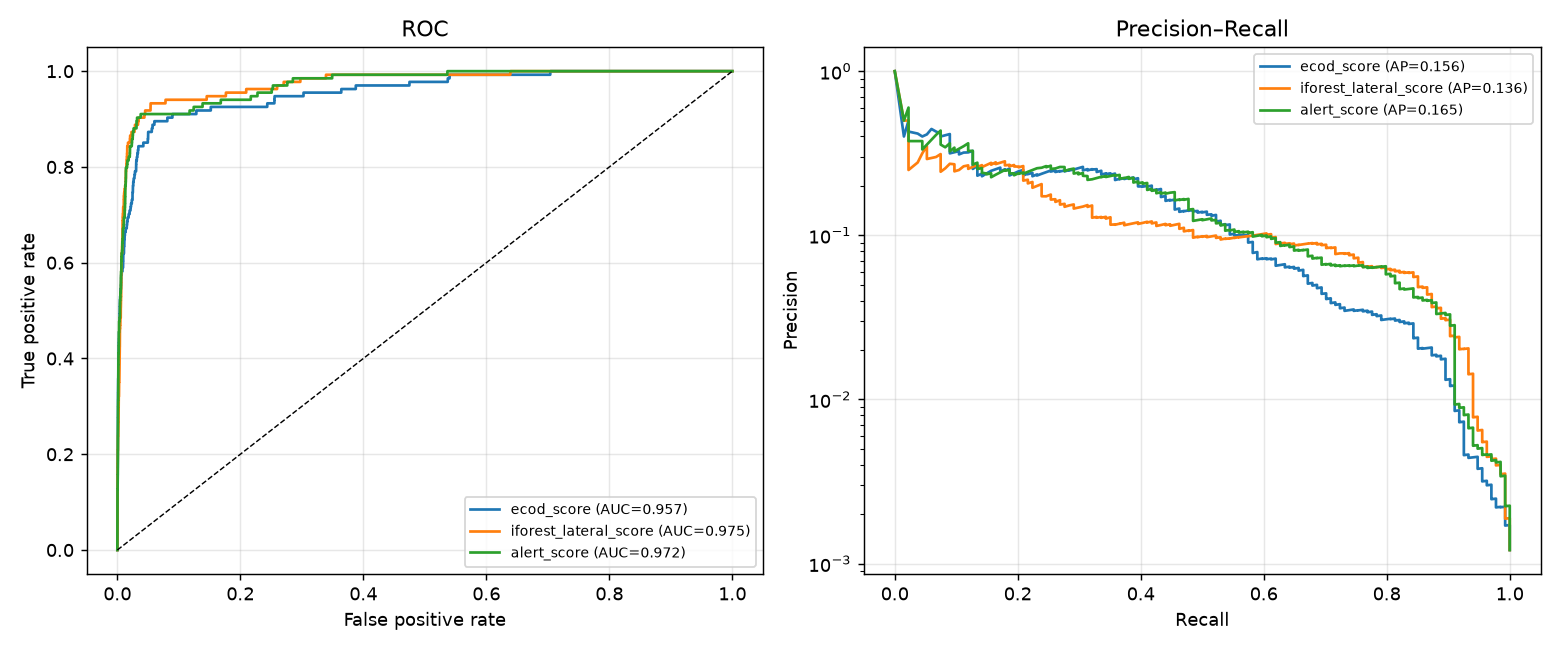

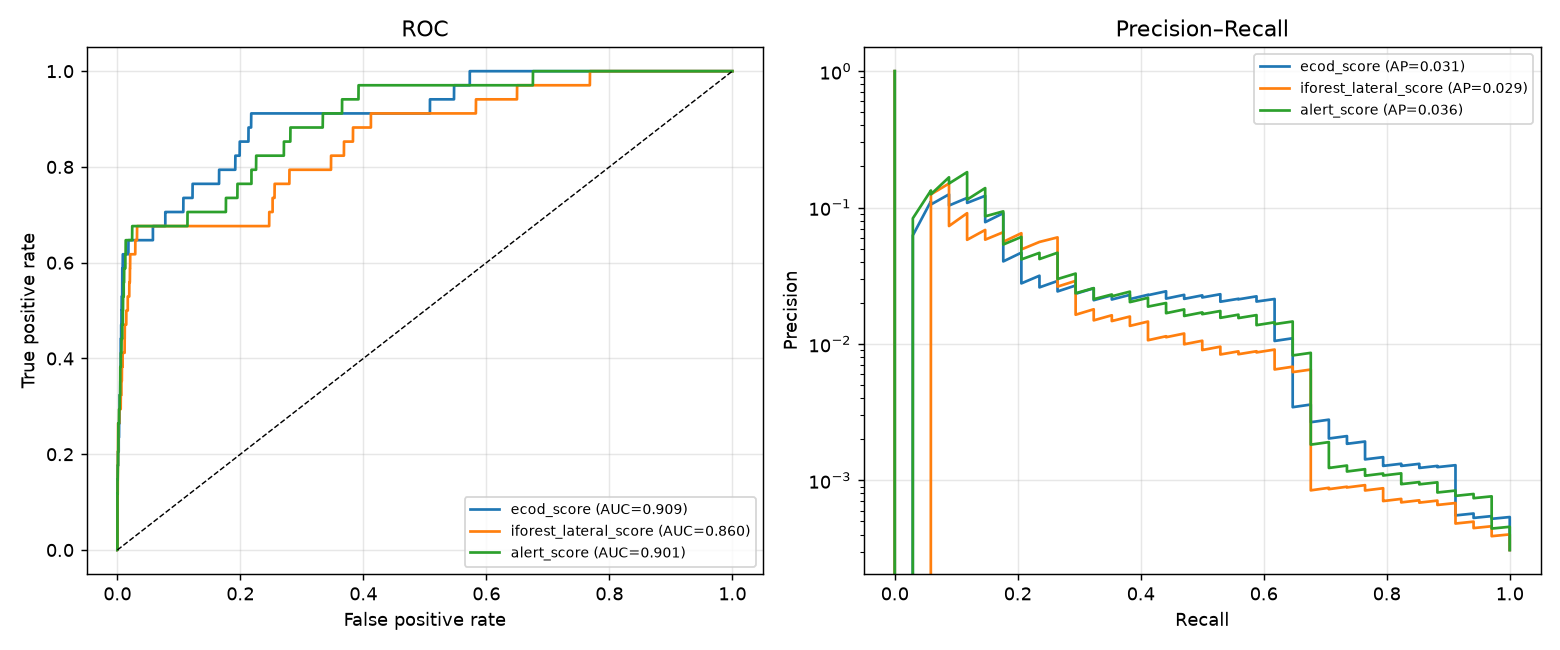

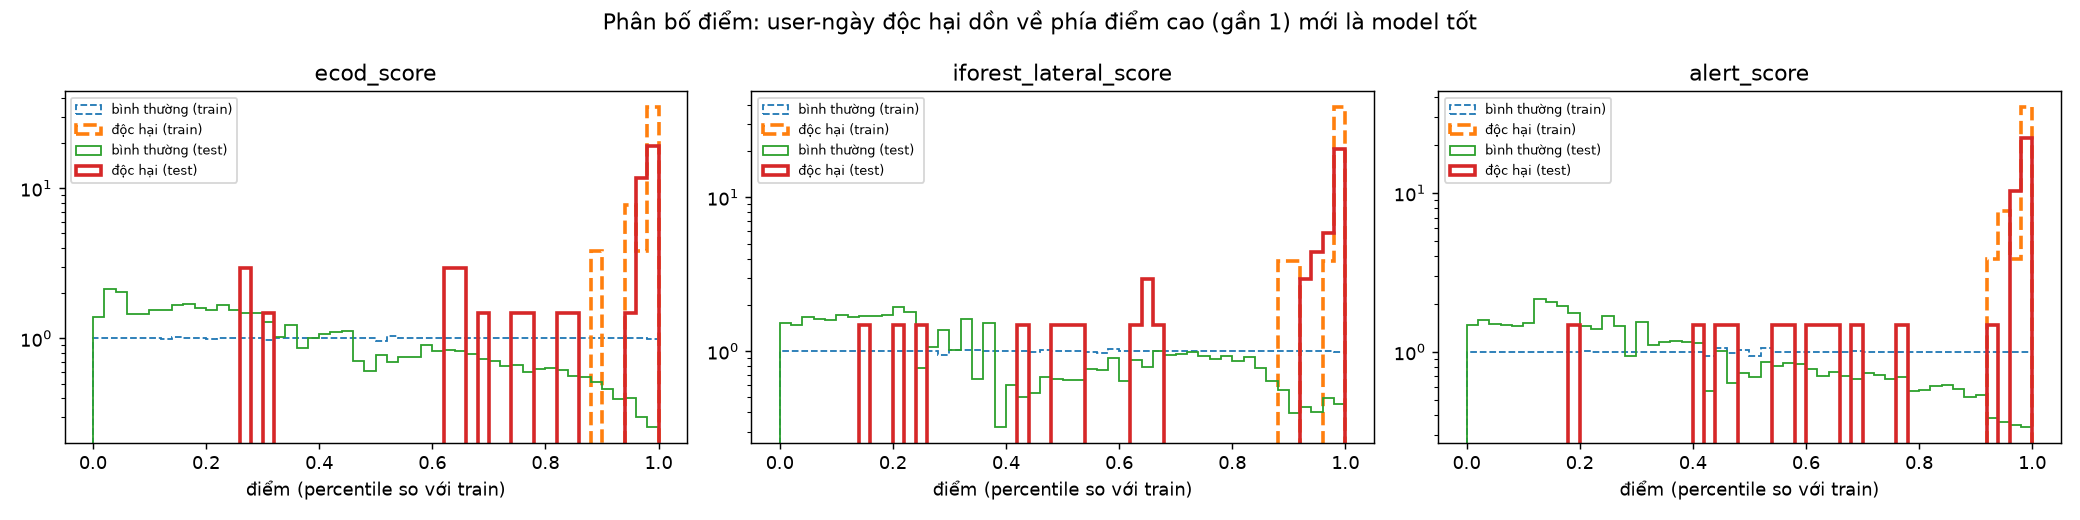

In [4]:
display(Image(REPORTS_DIR / 'lanl_val_roc_pr.png'))
display(Image(REPORTS_DIR / 'lanl_test_roc_pr.png'))
display(Image(REPORTS_DIR / 'lanl_score_dist.png'))

## 3. Tóm tắt (gồm bộ phân loại người/máy)

In [5]:
json.load(open(REPORTS_DIR / 'lanl_summary.json'))

{'variant': 'quar+fanin',
 'train_days': '1-7',
 'val_days': '8-19',
 'test_days': '20-29',
 'human_bot': {'accuracy': 0.9884461211978307,
  'roc_auc': 0.9992072487026337,
  'rows_train': 114386,
  'rows_test': 38169},
 'val': {'roc_auc': 0.9720042208517737,
  'pr_auc': 0.16537827098667524,
  'positives': 134,
  'total': 110807,
  'precision@50': 0.34,
  'recall@50': 0.12686567164179105,
  'precision@100': 0.25,
  'recall@100': 0.1865671641791045,
  'precision@500': 0.13,
  'recall@500': 0.48507462686567165,
  'precision@1000': 0.086,
  'recall@1000': 0.6417910447761194,
  'threshold': 0.99,
  'alerts': 393,
  'tp': 64,
  'fp': 329,
  'recall_at_threshold': 0.47761194029850745,
  'fpr_at_threshold': 0.0029727214406404454,
  'accounts_caught': 45,
  'accounts_total': 97,
  'alerts_per_day': 32.8,
  'accounts@10/day': 13,
  'accounts@25/day': 28,
  'accounts@50/day': 40,
  'redteam_mean_is_human_prob': 0.9455241990245082,
  'normal_mean_is_human_prob': 0.9509987029706506},
 'test': {'roc

## 4. Bảng điểm – 20 user-ngày bất thường nhất trong tập test

In [6]:
s = pd.read_parquet(PROCESSED_DIR / 'lanl_scores.parquet')
test = s[s.split == 'test']
test.sort_values('alert_score', ascending=False)[['src_user','day','alert_score','ecod_score','iforest_lateral_score','is_human_prob','is_redteam','top_reasons','n_events','n_new_src_comp','src_max_fanin','new_src_max_fanin','n_new_edge']].head(20)

,src_user,day,alert_score,ecod_score,iforest_lateral_score,is_human_prob,is_redteam,top_reasons,n_events,n_new_src_comp,src_max_fanin,new_src_max_fanin,n_new_edge
204869,U1718@?,21,0.999899,0.999884,0.999899,0.021764,False,"[n_dst_comp, n_new_dst_comp, n_new_edge]",624,120.0,3.0,125.0,335.0
193923,U1718@?,20,0.999899,0.999884,0.999899,0.567406,False,"[n_dst_comp, n_new_dst_comp, n_new_edge]",788,161.0,3.0,16.0,507.0
195622,U1653@DOM1,20,0.999899,0.999913,0.999884,0.999276,False,"[n_new_src_comp, n_new_edge_src_new, n_new_dst...",1810,51.0,8.0,6.0,49.0
208753,U1653@DOM1,21,0.999870,0.999841,0.999884,0.999782,False,"[n_new_src_comp, n_new_dst_comp, n_new_edge_sr...",1219,42.0,5.0,5.0,40.0
255162,U1718@?,26,0.999870,0.999841,0.999884,0.952534,False,"[n_dst_comp, n_new_dst_comp, n_new_edge]",386,81.0,4.0,97.0,258.0
217347,U1718@?,22,0.999827,0.999783,0.999884,0.484903,False,"[n_dst_comp, n_new_dst_comp, n_new_edge]",421,87.0,3.0,16.0,247.0
276676,U1718@?,28,0.999798,0.999668,0.999884,0.931386,False,"[n_new_dst_comp, n_new_edge, n_dst_comp]",158,36.0,1.0,3270.0,88.0
222775,U7135@C3794,22,0.999783,0.999668,0.999827,0.993202,False,"[ntlm_ratio, remote_ratio, new_src_ntlm_events]",7908,1.0,4.0,4.0,1.0
297660,U1718@?,29,0.999783,0.999639,0.999884,0.929595,False,"[n_new_dst_comp, n_new_edge, n_new_src_comp]",163,32.0,1.0,3245.0,93.0
231555,U7510@DOM1,23,0.999754,0.999754,0.999697,0.999961,False,"[n_new_edge_src_new, n_new_edge, n_new_src_comp]",1473,20.0,3.0,2.0,76.0


## 5. Xem dòng thời gian của 1 user bất kỳ (đổi tên user ở dưới)

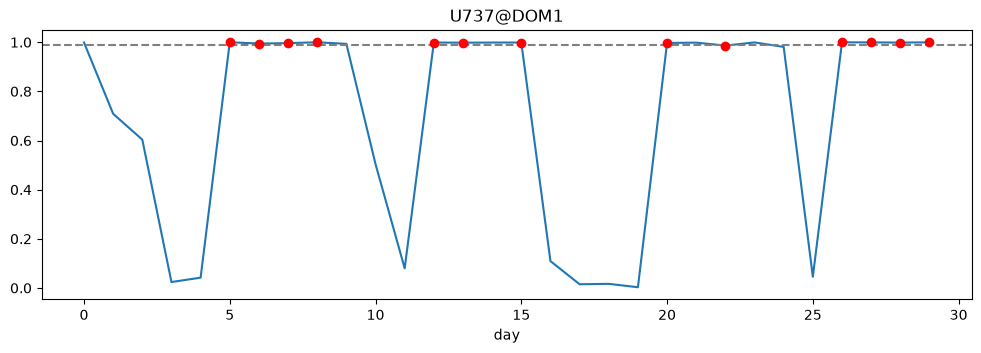

In [7]:
import matplotlib.pyplot as plt
USER = test.loc[test.is_redteam, 'src_user'].iloc[0]   # vd: 'U66@DOM1'
u = s[s.src_user == USER].sort_values('day')
ax = u.plot(x='day', y='alert_score', figsize=(12, 3.5), legend=False, title=USER)
ax.scatter(u.loc[u.is_redteam, 'day'], u.loc[u.is_redteam, 'alert_score'], color='red', zorder=3)
ax.axhline(0.99, ls='--', color='gray'); plt.show()

## 6. Feature nào quyết định & dữ liệu ban đầu (EDA)

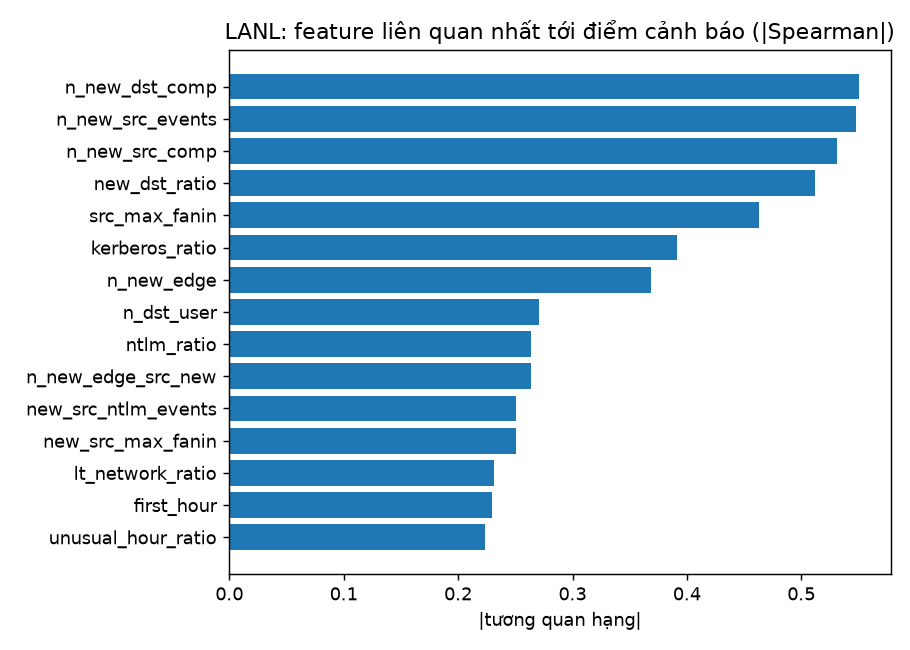

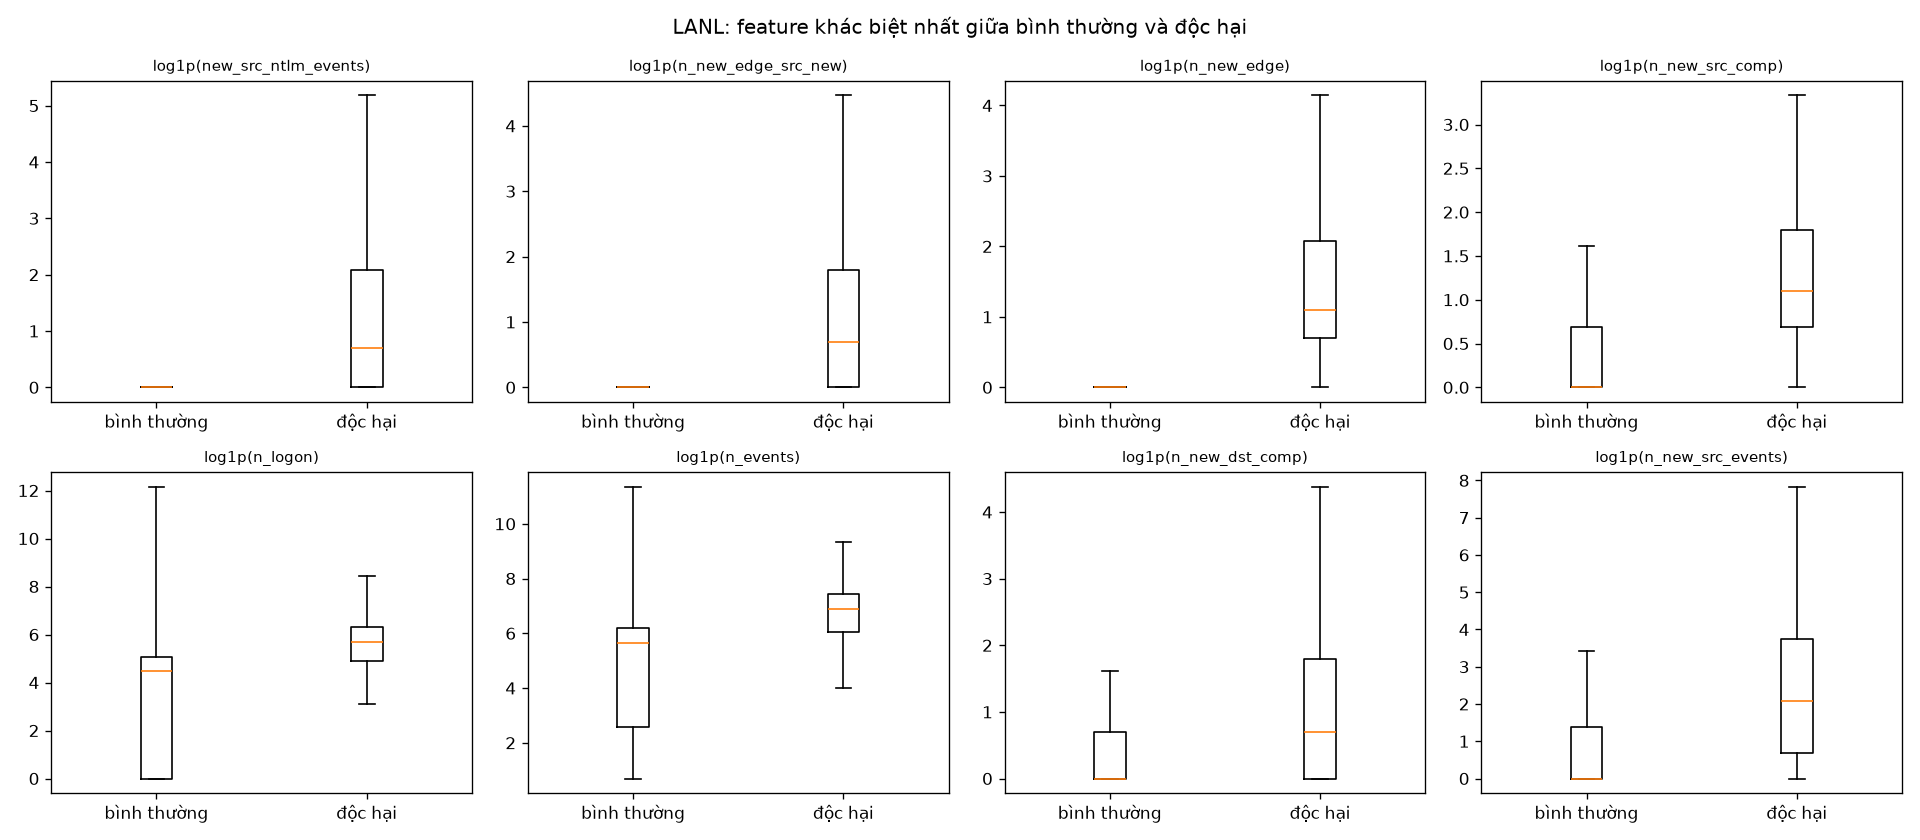

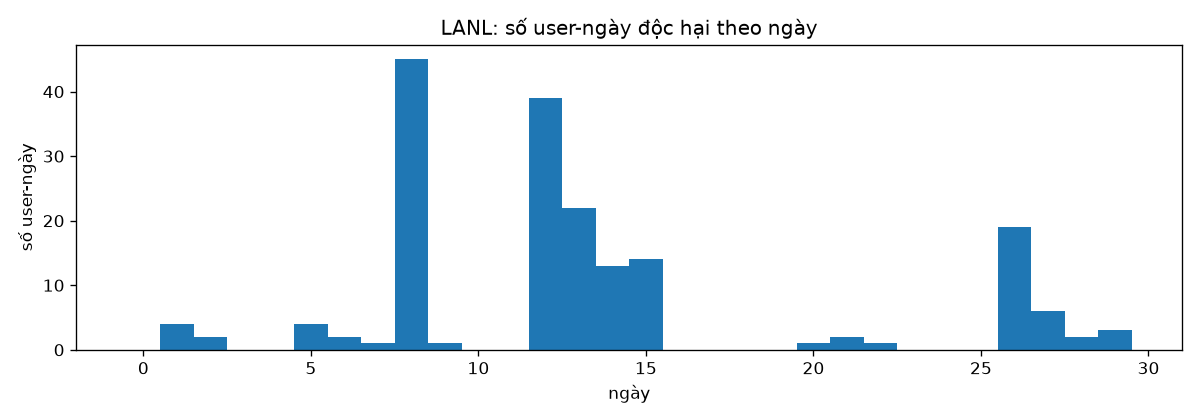

In [8]:
for f in ['lanl_feature_importance.png', 'lanl_eda_feature_compare.png', 'lanl_eda_labels_over_time.png']:
    display(Image(REPORTS_DIR / f))

## 7. Một cảnh báo xuất cho Người B (đúng schema)

In [9]:
alerts = json.load(open(REPORTS_DIR / 'alerts.json', encoding='utf-8'))
print(len(alerts), 'cảnh báo'); alerts[0]

407 cảnh báo


{'alert_id': 'lanl-20-00001',
 'timestamp': '2026-09-21T06:03:19Z',
 'user': 'U1653@DOM1',
 'src_host': 'C22837',
 'dst_host': 'C754',
 'source': 'ml',
 'rule_id': None,
 'anomaly_score': 0.9999,
 'is_human_prob': 0.9993,
 'severity': 'critical',
 'mitre': {'tactic': 'Lateral Movement',
  'technique_id': 'T1021',
  'technique_name': 'Remote Services'},
 'features': {'n_events': 1810.0,
  'n_dst_comp': 65.0,
  'n_new_dst_comp': 50.0,
  'new_dst_ratio': 0.7692,
  'n_new_src_comp': 51.0,
  'new_src_max_fanin': 6.0,
  'src_max_fanin': 8.0,
  'n_new_edge': 49.0,
  'fail_ratio': 0.0001,
  'ntlm_ratio': 0.2027,
  'remote_ratio': 0.3176,
  'unusual_hour_ratio': 0.0,
  'max_per_minute': 93.0,
  'top_reasons': ['n_new_src_comp', 'n_new_edge_src_new', 'n_new_dst_comp'],
  'ecod_score': 0.9999,
  'iforest_lateral_score': 0.9999,
  'ioc_hit': False,
  'dataset': 'LANL',
  'day': 20,
  'ground_truth_redteam': False},
 'agent_analysis': None}